# 06. Feature Engineering and Time-Based Split

**Procurement Intelligence Platform** | Notebook 06 of 13

How the forecasting problem is set up so that every model is tested fairly: the target, the horizons, the features, a leakage audit and a split that keeps 2025 completely unseen.

| | |
|---|---|
| **Inputs** | `marts.fct_weekly_section`, `marts.ml_features_weekly` (SQL feature store) |
| **Outputs** | Forecasting design, validated feature store, evaluation protocol |
| **Skills shown** | Forecast design, leakage prevention, feature engineering in SQL |

## 1. The forecasting task

| Item | Decision | Reason |
|---|---|---|
| Target | Requisition lines raised per section per week | Workload for buyers and the driver of backlog and cash |
| Level | 12 sections (plus business-unit and company totals by reconciliation) | Sections are smooth enough to forecast (notebook 05) |
| Horizon | 1 to 12 weeks ahead | A quarter is the planning window for buyers and Finance |
| Frequency | Weekly, weeks start on Monday | Matches the procurement meeting rhythm |
| Output | Point forecast **and** 80% and 95% prediction intervals | Planners need a range, not a single number |

Two more company-level targets are forecast in notebooks 10 and 11: **open backlog** and **weekly cash out**.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

Training data ends: 2024-12-30 | test period: 2025-01-06 to 2025-12-22
Validation origins (11): 2024-01-01 ... 2024-10-07
Test origins (10):       2024-12-30 ... 2025-09-08


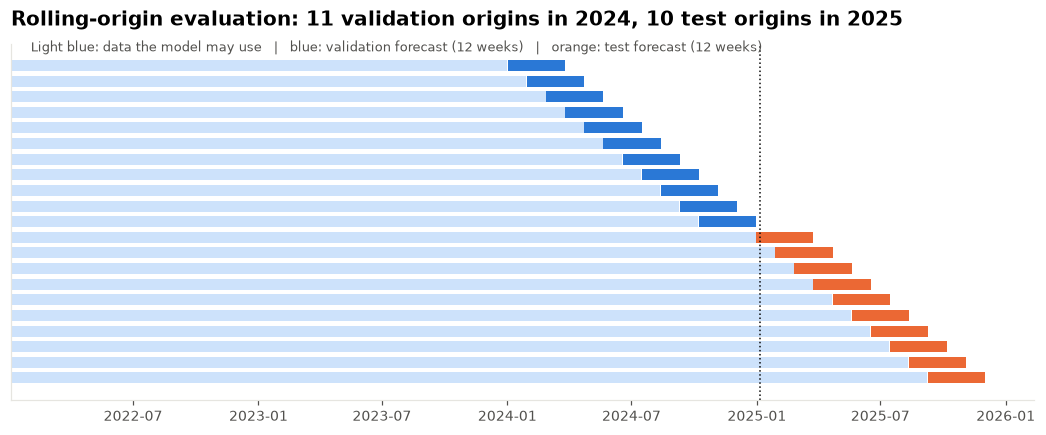

In [2]:
from p2p.forecasting import backtest as bt
from p2p.config import TRAIN_END, TEST_START, TEST_END
val, test = bt.validation_cutoffs(), bt.test_cutoffs()
print(f"Training data ends: {TRAIN_END} | test period: {TEST_START} to {TEST_END}")
print(f"Validation origins ({len(val)}): {val[0].date()} ... {val[-1].date()}")
print(f"Test origins ({len(test)}):       {test[0].date()} ... {test[-1].date()}")

fig, ax = plt.subplots(figsize=(12, 4.2))
for i, c in enumerate(val + test):
    y = len(val + test) - i
    ax.barh(y, (c - pd.Timestamp("2022-01-03")).days, left=pd.Timestamp("2022-01-03"), color="#cde2fb", height=0.7)
    ax.barh(y, 84, left=c + pd.Timedelta(days=1), color=SERIES[0] if c in val else SERIES[1], height=0.7)
ax.axvline(pd.Timestamp(TEST_START), color=BRAND["ink"], lw=1, ls=":")
ax.text(pd.Timestamp("2022-02-01"), len(val + test) + 0.9, "Light blue: data the model may use   |   blue: validation forecast (12 weeks)   |   orange: test forecast (12 weeks)",
        fontsize=8.5, color=BRAND["ink_2"])
ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_title("Rolling-origin evaluation: 11 validation origins in 2024, 10 test origins in 2025")
plt.show()

**Why rolling origins and not one split?** A single train/test split gives one number that depends on luck (which weeks happen to be in
the test). Rolling origins forecast 12 weeks ahead from 10 or 11 different dates and average the errors. Training always uses only data
before the origin (an expanding window), as it would in production.

**Two stages, two purposes:**

1. **Validation (2024):** choose and tune models, and pick ensemble members. 2025 is never looked at.
2. **Test (2025):** final, one-time evaluation. 2025 also contains a structural break (new marine contract) and a supplier suspension,
   so it tests robustness as well as accuracy.

A random split would put future weeks into training: the model would "know" the future and look far better than it really is.

## 2. Features for the machine-learning models

The machine-learning models use a **direct multi-horizon** strategy: one model per horizon h learns
`lines(t + h) = f(features known at t, calendar of week t + h)`. The features are computed in SQL in the dbt model
`ml_features_weekly`, so the warehouse is the single source of feature logic.

In [3]:
print((ROOT / "warehouse" / "models" / "marts" / "ml_features_weekly.sql").read_text()[:2400])

-- Feature store for the machine-learning forecasters (direct multi-horizon strategy).
-- Every feature on row t uses information available at the end of week t only.
-- Targets y_lead_h are the requisition lines h weeks ahead (h = 1..12).
with base as (select * from {{ ref('fct_weekly_section') }})
select
    section_id,
    business_unit,
    week_start                                                                   as origin_week,
    pr_lines                                                                     as y_t,
    lag(pr_lines, 1)  over w as lag_1,
    lag(pr_lines, 2)  over w as lag_2,
    lag(pr_lines, 3)  over w as lag_3,
    lag(pr_lines, 4)  over w as lag_4,
    lag(pr_lines, 8)  over w as lag_8,
    lag(pr_lines, 13) over w as lag_13,
    lag(pr_lines, 26) over w as lag_26,
    lag(pr_lines, 51) over w as lag_51,
    avg(pr_lines)        over (w rows between 3 preceding and current row)  as roll_mean_4,
    avg(pr_lines)        over (w rows between 12 preceding and c

In [4]:
catalogue = pd.DataFrame([
    ("y_t, lag_1 ... lag_51", "Lags", "Recent and same-season-last-year demand", "Past only"),
    ("roll_mean_4/13/52, roll_std_13, roll_max_13", "Rolling statistics", "Level, volatility and recent spikes", "Past only"),
    ("cm_roll_mean_4, cm_wo_roll_mean_4", "Driver history", "Breakdown activity drives corrective demand", "Past only"),
    ("project_roll_mean_13", "Driver history", "Recent project activity", "Past only"),
    ("fleet_utilisation, fleet_utilisation_chg_4", "Operations", "Busy fleets break more", "Past only"),
    ("fx_chg_13w", "Macro", "Currency stress changes buying behaviour", "Past only"),
    ("target_pm_planned_next_3w", "Known future", "Planned-maintenance schedule for the target week", "Known in advance"),
    ("target_sin/cos 1..3", "Known future", "Yearly seasonality (Fourier terms)", "Known in advance"),
    ("target_shutdown, target_budget_push, target_mrp_week", "Known future", "Calendar effects", "Known in advance"),
    ("section_code, bu_code", "Categorical", "Lets one global model learn section-specific patterns", "Static"),
], columns=["features", "family", "business rationale", "availability"])
display(catalogue)

,features,family,business rationale,availability
0,"y_t, lag_1 ... lag_51",Lags,Recent and same-season-last-year demand,Past only
1,"roll_mean_4/13/52, roll_std_13, roll_max_13",Rolling statistics,"Level, volatility and recent spikes",Past only
2,"cm_roll_mean_4, cm_wo_roll_mean_4",Driver history,Breakdown activity drives corrective demand,Past only
3,project_roll_mean_13,Driver history,Recent project activity,Past only
4,"fleet_utilisation, fleet_utilisation_chg_4",Operations,Busy fleets break more,Past only
5,fx_chg_13w,Macro,Currency stress changes buying behaviour,Past only
6,target_pm_planned_next_3w,Known future,Planned-maintenance schedule for the target week,Known in advance
7,target_sin/cos 1..3,Known future,Yearly seasonality (Fourier terms),Known in advance
8,"target_shutdown, target_budget_push, target_mrp_week",Known future,Calendar effects,Known in advance
9,"section_code, bu_code",Categorical,Lets one global model learn section-specific patterns,Static


## 3. Leakage audit: can a feature see the future?

The strongest check is empirical: recompute the feature store on data **truncated at a cutoff** and compare it with the full feature
store for all rows up to that cutoff. If any feature used future data, the values would differ.

In [5]:
from p2p.data import connect
compiled = (ROOT / "warehouse" / "target" / "compiled" / "p2p" / "models" / "marts" / "ml_features_weekly.sql").read_text()
cutoff = "2024-06-03"
truncated_sql = compiled.replace('"p2p"."marts"."fct_weekly_section"',
                                 f"(select * from marts.fct_weekly_section where week_start <= date '{cutoff}')")
with connect() as con:
    full = con.execute("select * from marts.ml_features_weekly").df()
    trunc = con.execute(truncated_sql).df()

feature_cols = [c for c in full.columns if c.startswith(("lag_", "roll_", "cm_", "project_", "fleet_", "fx_", "pm_")) or c == "y_t"]
key = ["section_id", "origin_week"]
a = full[full.origin_week <= pd.Timestamp(cutoff)].set_index(key)[feature_cols].sort_index()
b = trunc.set_index(key)[feature_cols].sort_index()
diff = (a - b).abs().max()
print(f"Rows compared: {len(a):,} | features compared: {len(feature_cols)}")
print("Features that changed when the future was removed:", list(diff[diff > 1e-9].index))

Rows compared: 1,524 | features compared: 21
Features that changed when the future was removed: []


**What we see.** Not a single feature value changes when the future is removed: all 21 features on 1,524 rows are identical. The SQL
windows only look backwards.

Two columns are forward-looking **by design** and are handled separately: the targets (`y_lead_h`), which the training code only uses
when the target week is on or before the cutoff, and the planned-maintenance schedule (`pm_planned_next_3w`), which is legitimately
known in advance because the maintenance plan is published weeks ahead.

## 4. Known-future covariates for statistical and neural models

In [6]:
from p2p.forecasting.features import known_future_exog
X = known_future_exog()
display(X[X.unique_id == "SEC04"].tail(5))

,unique_id,ds,pm_planned_next_3w,sin1,cos1,sin2,cos2,sin3,cos3,shutdown,budget_push,mrp_week
827,SEC04,2025-11-24,19,-0.482,0.876,-0.845,0.535,-0.998,0.061,0,1,0
828,SEC04,2025-12-01,15,-0.374,0.928,-0.693,0.721,-0.912,0.410,0,0,1
829,SEC04,2025-12-08,11,-0.259,0.966,-0.501,0.865,-0.709,0.706,0,0,0
830,SEC04,2025-12-15,4,-0.142,0.990,-0.280,0.960,-0.413,0.911,1,0,1
831,SEC04,2025-12-22,0,-0.022,1.000,-0.043,0.999,-0.065,0.998,1,0,0


## 5. How models are scored

| Metric | Formula (simplified) | Why |
|---|---|---|
| **MASE** (primary) | mean absolute error / in-sample error of the seasonal naive | Scale-free, comparable across sections, below 1 means better than the seasonal naive benchmark |
| **WAPE** | total absolute error / total actuals | Easy for managers: "we are off by X% of the volume" |
| **Bias** | (total forecast - total actuals) / total actuals | Systematic over- or under-forecasting; drives stock-outs or excess |
| **Pinball loss** | quantile loss averaged over 2.5%, 10%, 50%, 90%, 97.5% | Quality of the whole forecast distribution |
| **CRPS** | approximated as 2 x mean pinball loss | Single score for probabilistic forecasts |
| **Coverage 80% / 95%** | share of actuals inside the interval | Are the intervals honest? Target 0.80 and 0.95 |

Every model, from the naive benchmark to the foundation model, is wrapped into the same backtest engine with the signature
`fn(train, h, cutoff) -> forecasts with quantiles`, so the comparison is fair by construction.

In [7]:
import inspect
from p2p.forecasting.backtest import rolling_origin
print(inspect.getsource(rolling_origin))

def rolling_origin(fn: Forecaster, df: pd.DataFrame, origins: list[pd.Timestamp], name: str,
                   h: int = H, verbose: bool = False) -> pd.DataFrame:
    """Run `fn` at every origin and return forecasts joined with actuals."""
    out = []
    t0 = time.time()
    for c in origins:
        train = df[df.ds <= c]
        fc = fn(train, h, c)
        fc = _finish(fc)
        fc["cutoff"] = c
        fc["h"] = ((fc.ds - c).dt.days // 7).astype(int)
        out.append(fc[fc.h.between(1, h)])
        if verbose:
            print(f"{name}: origin {c.date()} done")
    res = pd.concat(out, ignore_index=True)
    res = res.merge(df[["unique_id", "ds", "y"]], on=["unique_id", "ds"], how="inner")
    res["model"] = name
    res.attrs["seconds"] = time.time() - t0
    return res



## 6. Summary

* Target, horizon, level and outputs are fixed and justified by the business need.
* 2024 is used for model choice (11 origins), 2025 only for the final test (10 origins).
* The SQL feature store passed the leakage audit: only the published maintenance plan looks ahead, by design.
* All models are scored with the same metrics, for both point accuracy and uncertainty.

**Next:** notebook 07 trains the baselines and the statistical models.